<a href="https://colab.research.google.com/github/NERO11110/mato-game/blob/main/%E8%AA%B2%E9%A1%8C04_36_MR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **的あてゲーム**


## **概要**

このプログラムは,ランダムに配置される的に向かって球を打ち出す放物線シミュレーションゲームである.プログラミングの基礎と物理演算を組み合わせ,ユーザーが実際に数値を入力して遊べるように作られている.主な機能として,起動時に「Easy」「Normal」「Hard」の3つの難易度から1つを選択する.難易度によって狙う的の大きさが変化し,位置も毎回ランダムに変わる仕組みである.次に,ユーザーは球の「初速度」と「角度」を入力する.ここでは,数字以外の文字や範囲外の数値が入力されてもプログラムが強制終了しないよう,正しい値が入力されるまで再入力を促す例外処理機能が備わっている.
入力後は重力加速度や反発係数を考慮した物理演算が行われ,地面で最大3回までバウンドする球の軌道データが作られる.最終的にそのデータをもとにアニメーションが表示され,球が的に当たれば「HIT」,外れれば「MISS」と画面に出る機能もある.

## **操作方法**

実行が進むと,画面に入力を求める案内文が表示される.難易度の選択画面では「e」「n」「h」のいずれかを,その後の初速度と角度の画面ではそれぞれ適切な数値を入力欄に打ち込み,その都度「Enter」キーを押して確定させる.このとき,入力は必ず半角で行う必要がある.全角で入力するとエラーメッセージが表示され,正しい入力が行われるまで同じ質問が繰り返される仕組みになっている.実行時の留意点として,すべての入力を終えたあとにアニメーションが表示されるまで数秒の待ち時間が発生する.これはプログラムが裏側で何百コマもの動画データを計算して組み立てているためであり,フリーズではないのでそのまま待つ必要がある.また,処理速度によっては時々画面に表示される内容の順番がおかしくなることがあるが,数秒までは正しく処理されるため,実行から最大20秒ほど待つ場合がある.

## **制作者のコメント**

このプログラムの最大のアピールポイントは,まだプログラミングを学び始めて日が浅い段階で,ユーザーが快適に遊べるゲームシステムで生成AIを補助として使用したが,ほぼ自力で構築した点である.特に工夫した点は二つある.一つ目は,ユーザーが間違えて文字を入力したり,範囲外の数値を指定したりしてもプログラムが強制終了しないように,条件分岐や例外処理を何重にも重ねて鉄壁のガードを作ったことである.二つ目は,関数内で外側の変数を書き換える手法として,要素が一つだけのリストを作成してその中身を更新するという,リストの性質を応用したトリッキーな解決策を自力で見つけてAIに質問しながら実装したことである.一方で,最も苦労した部分はアニメーション機能の仕様理解であった,第11回授業の最後にあった斜方投射のプログラムをかなり参考にした.しかし,自分なりの理解で作成してみたが,画面の描画が重くならないように画面クリア処理を挟むタイミングの調整には非常に苦戦し,何度もエラーを出して試行錯誤を繰り返した．最初はただの地味な物理計算の課題だったが,「どうせなら楽しいゲームにしたい」と思い立ち,夜遅くまで夢中でコードを書き足していった.黒い画面に向き合い続け,初めて思い通りの放物線が的へ綺麗に命中した瞬間の達成感は今でも忘れられない.自分の手で動く作品を生み出すという,プログラミングの本質的な楽しさに触れることができた最高の開発経験となった.
## **作成時間**

作成時間：**約20時間**

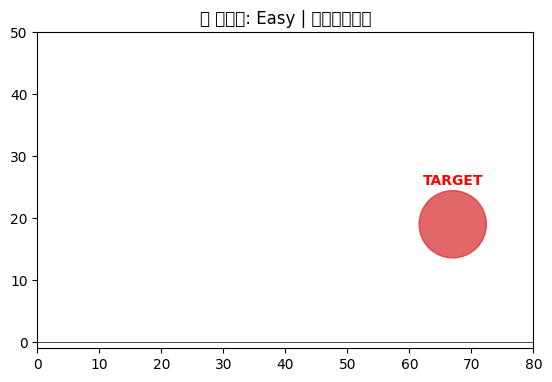


🚀 打ち出す初速度 (m/s): 40
📐 打ち出す角度 [0-90]: 30



In [ ]:
%reset -f
import math
import random
import matplotlib.pyplot as plt
import matplotlib.animation as anim
import IPython
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="IPython.core.pylabtools")
# 処理するときの処理文を消すため

while True:
    plt.close('all')
    IPython.display.clear_output(wait=True)
    # この2文で処理により重くなるのを避ける

    while True:
        print("="*40)
        print("🎯難易度を選んでね")
        print("  [e] Easy   (大きな的 🟢)")
        print("  [n] Normal (普通の的 🟡)")
        print("  [h] Hard   (小さな的 🔴)")
        print("="*40)
        # 選択画面を豊かに
        diff = input("🎮 難易度を選んでね (e/n/h): ").strip().lower()

        if diff in ['e', 'n', 'h']:
            # e,n,hの3つをリストに入れて，diffが満たすか見る
            break
        else:
            print("\n❌ エラー: 'e', 'n', 'h' のいずれかを入力してください！\n")
        # e,n,h以外の文字を入力されたときに想定した文字を入力させる

    if diff == 'e':
        goal_size = random.uniform(4.0, 6.0)
        diff_label = "Easy"
    elif diff == 'h':
        goal_size = random.uniform(0.5, 1.2)
        diff_label = "Hard"
    else:
        goal_size = random.uniform(2.0, 3.5)
        diff_label = "Normal"
    # diffにはe,n,hのどれかがあるから，的の大きさを調節

    goal_x = random.randint(65, 75)
    goal_y = random.randint(5, 25)
    # 的の位置は毎回ランダム

    IPython.display.clear_output(wait=True)
    fig_pre, ax_pre = plt.subplots()
    ax_pre.set_xlim(0, 80)
    ax_pre.set_ylim(-1, 50)
    ax_pre.set_aspect('equal', adjustable='box')
    ax_pre.axhline(0, c='black', lw=0.5)
    # アニメーションを行う土台作り．アスペクト比を1：1，x軸を太くしている

    goal_circle_pre = plt.Circle((goal_x, goal_y), goal_size, color='tab:red', alpha=0.7)
    # 第一引数が位置，第二引数が大きさ，第三引数が色，第四引数が透明度
    ax_pre.add_patch(goal_circle_pre)
    ax_pre.text(goal_x, goal_y + goal_size + 1, "TARGET", color='red', ha='center', weight='bold')
    # 第一引数がx座標，第二引数がy座標，第三引数が文字，第四引数が色，第五引数が設定したx座標と文字の中央を合わせる，第六引数は文字の太さ
    ax_pre.set_title(f"🎯 難易度: {diff_label} | 的に当てろ！")

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=UserWarning)
        IPython.display.display(fig_pre)
    # 重要度の低い警告文を消す
    plt.close(fig_pre)

    print("\n" + "="*40)
    while True:
        try:
            v0 = float(input("🚀 打ち出す初速度 (m/s): "))
            if v0 < 0:
                print("❌ エラー: 速度は0以上の数値を入力してください。")
                continue
            break
        except ValueError:
            print("❌ エラー: 有効な『数字』を入力してください！")
    # ０未満や数字以外を入力したら再度入力

    while True:
        try:
            theta_deg = float(input("📐 打ち出す角度 [0-90]: "))
            if not (0 <= theta_deg <= 90):
                print("❌ エラー: 角度は 0度 から 90度 の間で入力してください。")
                continue
            break
        except ValueError:
            print("❌ エラー: 有効な『数字』を入力してください！")
    print("="*40 + "\n")
    # 同様に，０から９０以外の数字や数字以外は再度入力

    g = 9.8      # 重力加速度
    dt = 0.05    # 1コマ当たりの進行速度
    theta_rad = math.radians(theta_deg) # 数字の角度をπを用いたラジアンにする

    vx = v0 * math.cos(theta_rad)
    vy = v0 * math.sin(theta_rad)
    # x,y方向の速度
    now_x = 0.0
    now_y = 0.0

    arr_x = [now_x]
    arr_y = [now_y]
    # スタートはどちらも座標は（０，０）

    bounce_count = 0  # バウンド回数
    e = 0.6     # 反発係数

    for _ in range(300):
        # 0から299の300が代入される，＿はカウント変数を必要しないから変数なし
        now_x = now_x + vx * dt
        vy = vy - g * dt
        now_y = now_y + vy * dt
        # そのコマの時のx,y方向の座標の計算

        if now_y <= 0:
            now_y = 0.0
            vy = -vy * e
            bounce_count += 1
            if bounce_count >= 3 or abs(vy) < 0.5:
                for _ in range(15):
                    arr_x.append(now_x)
                    arr_y.append(0.0)
                break
        # y座標が０以下なら，反発係数を考慮してバウンドし，バウンド回数を数え，バウンドは3回までにする．

        if now_x > 90:
            break
        # 枠外に行ったら終了

        arr_x.append(now_x)
        arr_y.append(now_y)
        # 今の座標をリストに入れる

    frames_count = len(arr_x)
    # コマ数カウント，このリストのMAXは299だがlenなので300が代入される→0コマから299コマの300コマを扱う

    has_hit_at_all = False
    for x, y in zip(arr_x, arr_y):
        if math.sqrt((x - goal_x)**2 + (y - goal_y)**2) <= goal_size:
            has_hit_at_all = True
            break
    # 球と的の距離を計算，1度でも的に当たっていたらTrueにしておく

    fig, ax = plt.subplots()
    # figが画用紙，axが書く内容を入れる変数
    already_hit = [False]
    # pythonの性質上，関数内と外で変数の変更ができないから，要素が1つのリストを作って変更できるようにする．ゲームの結果はミスが多いからFalseをデフォ

    ax.set_xlim(0, 80)
    ax.set_ylim(-1, 50)
    ax.set_aspect('equal', adjustable='box')
    ax.axhline(0, c='black', lw=0.5)
    # 背景の作画

    goal_circle = plt.Circle((goal_x, goal_y), goal_size, color='tab:red', alpha=0.7)
    ax.add_patch(goal_circle)
    #　的の作画
    ax.text(goal_x, goal_y + goal_size + 1, "TARGET", color='red', ha='center', weight='bold')
    # 的の上の"TARGET"の作画
    ax.set_title(f"🚀 的に当てろ！ ({diff_label} Mode)", color="black", fontsize=12)

    line, = ax.plot([], [], color='tab:blue', linestyle=':', alpha=0.5)
    #　コンマの意味はアンパック．薄い軌道の線の作画
    point = ax.scatter([], [], color='tab:blue', s=50, zorder=3)
    # line,のほうはリストだからアンパック．こっちはリストじゃないからアンパックなし

    result_text = ax.text(40, 25, "", color="blue", fontsize=32,
                          weight='bold', ha='center', va='center',
                          bbox=dict(facecolor='white', alpha=0.8, edgecolor='blue', boxstyle='round,pad=0.5'))
    result_text.set_visible(False)

    def frame(i):
        line.set_data(arr_x[:i+1], arr_y[:i+1])
        point.set_offsets([[arr_x[i], arr_y[i]]])

        current_distance = math.sqrt((arr_x[i] - goal_x)**2 + (arr_y[i] - goal_y)**2)
        # 的と球の距離計算
        if current_distance <= goal_size:
            already_hit[0] = True
        # 的と球の距離と的の大きさを比較して的の大きさのほうが大きい→的に当たっている
        passed_line = arr_x[i] >= goal_x
        # 球が的の鉛直線上を通過したらTrue，通過していなければFalse

        if already_hit[0]:
            result_text.set_text("✨ HIT!! ✨")
            result_text.set_color("green")
            result_text.get_bbox_patch().set_edgecolor("green")
            result_text.set_visible(True)
        elif passed_line and not has_hit_at_all:
        # 的の鉛直線上を球が通過した且つ一度も当たっていない時に発動
            result_text.set_text("💦 MISS... 💦")
            result_text.set_color("blue")
            result_text.get_bbox_patch().set_edgecolor("blue")
            result_text.set_visible(True)
        elif i == frames_count - 1 and not has_hit_at_all:
        # 最後のコマは299コマだが，先の代入で300になっているから-1→最終コマ且つ一度も当たっていない時に発動
            result_text.set_text("💦 MISS... 💦")
            result_text.set_color("blue")
            result_text.get_bbox_patch().set_edgecolor("blue")
            result_text.set_visible(True)

    ani = anim.FuncAnimation(fig, frame, interval=30, frames=frames_count)
    # 第一引数は使う画用紙，第二引数は1コマの内容，第三引数はコマをめくる速度，第四引数は総コマ数
    plt.close(fig)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=UserWarning)
        video_html = IPython.display.HTML(ani.to_jshtml())
        # 重要度の低い警告文の削除

    IPython.display.display(video_html)

    while True:
        print("\n" + "="*30)
        retry = input("🎮 再チャレンジする? (y/n): ").strip().lower()
        print("="*30 + "\n")
        # 再チャレンジするか

        if retry in ['y', 'n']:
            break
        # y,nのどちらかが選ばれたら，このwhileを終わらせる
        else:
            print("❌ エラー: 'y' または 'n' で答えてね！")
        # y,n以外が入力されたら再入力

    if retry == 'n':
        print("🎉 お疲れ様でした！ゲームを終了します。")
        break
    # nが選ばれたら，一番上のwhileが終了→一連の処理を終わらせる